In [13]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
from tqdm import tqdm

In [14]:
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {device}")

Using device: mps


In [15]:
batch_size = 128
learning_rate = 3e-4
n_epochs = 1
n_classes = 5
crop_size = 32

In [ ]:
transform = transforms.Compose([
    transforms.ToTensor(),
])

train_dataset = datasets.ImageFolder(root="crops_train_annotations", transform=transform)
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=1)

train_iterator = iter(train_loader)

In [17]:
from torchvision.models import resnet18
from torchvision.models import ResNet18_Weights   # Import des poids officiels

# Charger un modèle préentraîné
model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)

# # différentes couches du modèle
# for name, layer in model.named_children():
#     print(name, ":", layer)

# remplacer la dernière couche pour avoir le bon nombre de classe et pas les 1000 de ImageNet
in_features = model.fc.in_features
model.fc = nn.Linear(in_features, n_classes)

total_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters in the model: {total_params/1e6:.6f} million")

Total parameters in the model: 11.179077 million


In [ ]:
model = model.to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
criterion = nn.CrossEntropyLoss()

train_loss_list = []
train_acc_list = []

In [ ]:
def get_accuracy(split="train"):

    if split == "train":
        iterator = train_iterator
        loader = train_loader
    else:
        print("split non définit")

    model.eval()
    with torch.no_grad():
        try:
            x, y = next(iterator)     
        except StopIteration:
            iterator = iter(loader)
            x, y = next(iterator)
        x, y = x.to(device), y.to(device)
        y_hat = model(x)
        probs = torch.softmax(y_hat, dim=1)
        preds = torch.argmax(probs, dim=1)
        n_correct += (preds.view(-1) == y.view(-1)).float().sum().item()
        n_total = y.shape[0]
    accuracy = n_correct / n_total
    model.train()

    return accuracy



# PROBLEME LE TRAIN_ITERATOR N'EST PAS MODIFIÉ DU COUP ON VA DEVOIR FAIRE iter(loader) A CHAQUE TOUR DE BOUCLE ET C'EST LENT

100%|██████████| 3556/3556 [03:05<00:00, 19.18it/s]

tensor(0.8153)


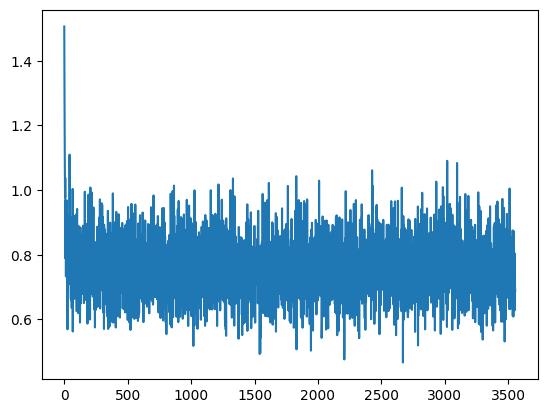

In [ ]:
for epoch in range(n_epochs):
    for i, (imgs, classes) in tqdm(enumerate(train_loader), total=len(train_loader)):

        imgs, classes = imgs.to(device), classes.to(device)

        # imgs = torch.randn_like(imgs, device=device)

        output = model(imgs)
        loss = criterion(output, classes)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if i % 10 == 0:
            train_loss_list.append(loss.item())
            train_acc_list.append(get_accuracy("train"))



    print(torch.tensor(train_loss_list[:100]).mean())
    
    plt.subplot(1, 2, 1)
    plt.plot(train_loss_list, c="blue")
    plt.subplot(1, 2, 2)
    plt.plot(train_acc_list, c="blue")
    plt.show()


tensor(0.8366)


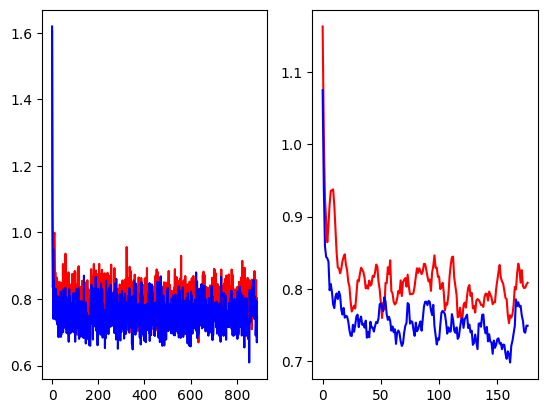

In [28]:

print(torch.tensor(save_list[:100]).mean())
maxi = max(len(save_list), len(train_loss_list))

s = 5
save_list_moy = [sum(save_list[i:i+s])/s for i in range(int(len(save_list)/s))]
train_loss_list_moy = [sum(train_loss_list[i:i+s])/s for i in range(int(len(train_loss_list)/s))]

plt.subplot(1, 2, 1)
plt.plot(save_list[:maxi], c="red")
plt.plot(train_loss_list[:maxi], c="blue")
plt.subplot(1, 2, 2)
plt.plot(save_list_moy[:maxi//s], c="red")
plt.plot(train_loss_list_moy[:maxi//s], c="blue")
plt.show()